## Why BraTS 2020 dataset:
The easiest, most accessible, well-supported version of BraTS for practicing U-Net tumor segmentation.

- This is the sweet spot for learning
- Freely available through multiple platforms
- Well-organized 3D volumes (same modalities as 2015)
- Clean labels + consistent preprocessing
- Widely used in recent papers and tutorials
- Many open-source TensorFlow/PyTorch examples available
- Still realistic and challenging

The easiest source is Kaggle:

- https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
- Downloading the training and validation data without any registration with MICCAI.

Great for:

- practicing 2D and 3D U-Net
- testing new architectures
- doing data augmentation
- reproducible experiments

In [12]:
import os
path = r"C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\raw\BraTS2020_TrainingData/"
print(os.listdir(path))

['BraTS20_Training_001', 'BraTS20_Training_002', 'BraTS20_Training_003', 'BraTS20_Training_004', 'BraTS20_Training_005', 'BraTS20_Training_006', 'BraTS20_Training_007', 'BraTS20_Training_008', 'BraTS20_Training_009', 'BraTS20_Training_010', 'BraTS20_Training_011', 'BraTS20_Training_012', 'BraTS20_Training_013', 'BraTS20_Training_014', 'BraTS20_Training_015', 'BraTS20_Training_016', 'BraTS20_Training_017', 'BraTS20_Training_018', 'BraTS20_Training_019', 'BraTS20_Training_020', 'BraTS20_Training_021', 'BraTS20_Training_022', 'BraTS20_Training_023', 'BraTS20_Training_024', 'BraTS20_Training_025', 'BraTS20_Training_026', 'BraTS20_Training_027', 'BraTS20_Training_028', 'BraTS20_Training_029', 'BraTS20_Training_030', 'BraTS20_Training_031', 'BraTS20_Training_032', 'BraTS20_Training_033', 'BraTS20_Training_034', 'BraTS20_Training_035', 'BraTS20_Training_036', 'BraTS20_Training_037', 'BraTS20_Training_038', 'BraTS20_Training_039', 'BraTS20_Training_040', 'BraTS20_Training_041', 'BraTS20_Traini

In [13]:
subjects = sorted(os.listdir(path))
len(subjects), subjects[:5]

(371,
 ['BraTS20_Training_001',
  'BraTS20_Training_002',
  'BraTS20_Training_003',
  'BraTS20_Training_004',
  'BraTS20_Training_005'])

In [39]:
import nibabel as nib

def load_modality(folder, keyword):
    files = os.listdir(folder)
    for f in files:
        if keyword.lower() in f.lower() and f.endswith(".nii"):
            return nib.load(os.path.join(folder, f)).get_fdata()
    raise FileNotFoundError(f"No file found for {keyword}")
sub_path = r"C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\raw\BraTS2020_TrainingData/BraTS20_Training_355/"
subject_folder = sub_path

flair = load_modality(subject_folder, "flair")
t1    = load_modality(subject_folder, "t1") 
t1ce  = load_modality(subject_folder, "t1ce")
t2    = load_modality(subject_folder, "t2")
seg   = load_modality(subject_folder, "seg")

print(flair.shape, seg.shape)


(240, 240, 155) (240, 240, 155)


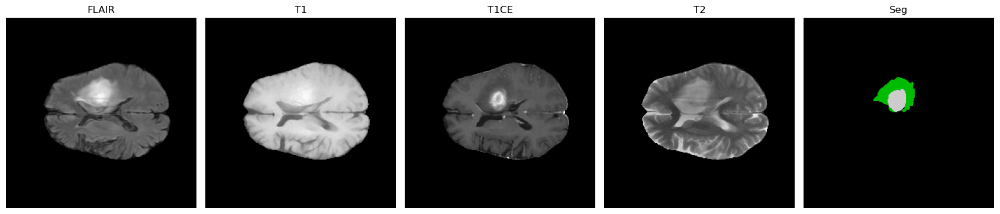

In [40]:
import numpy as np
import matplotlib.pyplot as plt
slice_idx = 82

plt.figure(figsize=(17,4))

plt.subplot(1,5,1); plt.imshow(flair[:,:,slice_idx], cmap="gray"); plt.title("FLAIR"); plt.axis("off")
plt.subplot(1,5,2); plt.imshow(t1[:,:,slice_idx],    cmap="gray"); plt.title("T1");    plt.axis("off")
plt.subplot(1,5,3); plt.imshow(t1ce[:,:,slice_idx],  cmap="gray"); plt.title("T1CE");  plt.axis("off")
plt.subplot(1,5,4); plt.imshow(t2[:,:,slice_idx],    cmap="gray"); plt.title("T2");    plt.axis("off")
plt.subplot(1,5,5); plt.imshow(seg[:,:,slice_idx],   cmap="nipy_spectral"); plt.title("Seg"); plt.axis("off")

plt.tight_layout()
plt.show()


## Step 4) Preprocess volumes and turn them into 2D slices (per subject):

For one subject, go from 3D volumes to normalized 2D slices suitable for a 2D U-Net.
* 4.1. Set the base path and list subjects
* 4.2. Robust loader for one subject (handles .nii or .nii.gz)
* 4.3. Stack modalities and make a binary mask
* 4.4. Intensity normalization (per modality, per subject)
* 4.5. Extract 2D slices with tumor
* 4.6. Visual sanity check of slices (visualize one slice set (4 inputs + mask))

In [16]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

base_training = r"C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\raw\BraTS2020_TrainingData"

subjects = sorted([d for d in os.listdir(base_training) if os.path.isdir(os.path.join(base_training, d))])
print("Number of subjects:", len(subjects))
print("First 5:", subjects[:5])


Number of subjects: 369
First 5: ['BraTS20_Training_001', 'BraTS20_Training_002', 'BraTS20_Training_003', 'BraTS20_Training_004', 'BraTS20_Training_005']


In [17]:
def load_nifti_with_suffix(folder, subject_name, suffix):
    """
    Tries to load subject_name + '_' + suffix with .nii or .nii.gz
    Returns a numpy array.
    """
    for ext in [".nii", ".nii.gz"]:
        path = os.path.join(folder, f"{subject_name}_{suffix}{ext}")
        if os.path.exists(path):
            img = nib.load(path)
            return img.get_fdata()
    raise FileNotFoundError(f"Could not find file for {subject_name}_{suffix} in {folder}")


In [18]:
subject = subjects[0]
subject_folder = os.path.join(base_training, subject)
print("Using subject:", subject_folder)

flair = load_nifti_with_suffix(subject_folder, subject, "flair")
t1    = load_nifti_with_suffix(subject_folder, subject, "t1")
t1ce  = load_nifti_with_suffix(subject_folder, subject, "t1ce")
t2    = load_nifti_with_suffix(subject_folder, subject, "t2")
seg   = load_nifti_with_suffix(subject_folder, subject, "seg")

print("Shapes:", flair.shape, seg.shape)


Using subject: C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\raw\BraTS2020_TrainingData\BraTS20_Training_001
Shapes: (240, 240, 155) (240, 240, 155)


In [19]:
# Stack modalities as channels: (H, W, S, 4)
volume = np.stack([flair, t1, t1ce, t2], axis=-1)
print("Volume shape:", volume.shape)

# Binary mask: 1 if any tumor label, 0 otherwise
# BraTS labels are usually {0, 1, 2, 4}
mask = (seg > 0).astype(np.uint8)
print("Mask shape:", mask.shape, "Unique labels:", np.unique(seg), "Binary:", np.unique(mask))


Volume shape: (240, 240, 155, 4)
Mask shape: (240, 240, 155) Unique labels: [0. 1. 2. 4.] Binary: [0 1]


In [20]:
def normalize_volume_zscore(volume_4d):
    """
    volume_4d: (H, W, S, C)
    Z-score normalization per channel using non-zero voxels.
    Returns float32 volume.
    """
    vol = volume_4d.astype(np.float32).copy()
    H, W, S, C = vol.shape

    for c in range(C):
        channel = vol[..., c]
        nonzero = channel > 0
        if np.any(nonzero):
            mean = channel[nonzero].mean()
            std = channel[nonzero].std()
            channel[nonzero] = (channel[nonzero] - mean) / (std + 1e-8)
            vol[..., c] = channel
    return vol

volume_norm = normalize_volume_zscore(volume)
print("Normalized volume stats per channel:")
for c in range(volume_norm.shape[-1]):
    arr = volume_norm[..., c]
    nz = arr[arr != 0]
    print(f"Channel {c}: mean={nz.mean():.3f}, std={nz.std():.3f}")


Normalized volume stats per channel:
Channel 0: mean=0.000, std=1.000
Channel 1: mean=-0.000, std=1.000
Channel 2: mean=0.000, std=1.000
Channel 3: mean=0.000, std=1.000


In [21]:
def volume_to_tumor_slices(volume_4d, mask_3d, min_tumor_pixels=100):
    """
    volume_4d: (H, W, S, C)
    mask_3d:   (H, W, S), binary {0,1}
    Returns:
       X: (N_slices, H, W, C)
       y: (N_slices, H, W, 1)
    Keeps slices with at least `min_tumor_pixels` positive voxels.
    """
    H, W, S, C = volume_4d.shape
    X_list = []
    y_list = []

    for s in range(S):
        m = mask_3d[:, :, s]
        if m.sum() < min_tumor_pixels:
            continue
        x = volume_4d[:, :, s, :]          # (H, W, C)
        y = m[:, :, None].astype(np.uint8) # (H, W, 1)
        X_list.append(x)
        y_list.append(y)

    if len(X_list) == 0:
        return None, None

    X = np.stack(X_list, axis=0)
    y = np.stack(y_list, axis=0)
    return X, y

X_slices, y_slices = volume_to_tumor_slices(volume_norm, mask, min_tumor_pixels=100)
if X_slices is not None:
    print("X_slices shape:", X_slices.shape)  # (N, H, W, 4)
    print("y_slices shape:", y_slices.shape)  # (N, H, W, 1)
else:
    print("No tumor slices found for this subject with the given threshold.")


X_slices shape: (78, 240, 240, 4)
y_slices shape: (78, 240, 240, 1)


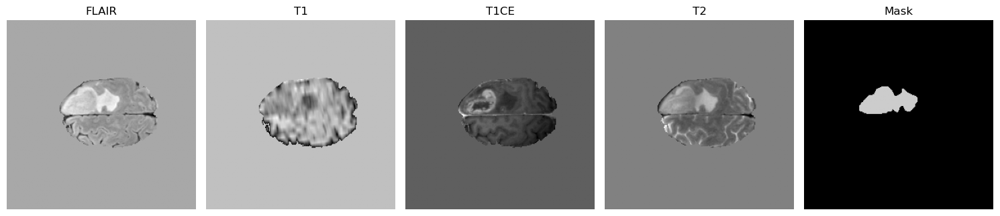

In [38]:
idx = np.random.randint(0, X_slices.shape[0])

img = X_slices[idx]  # (H, W, 4)
msk = y_slices[idx][:, :, 0]  # (H, W)

plt.figure(figsize=(15,4))

titles = ["FLAIR", "T1", "T1CE", "T2"]
for c in range(4):
    plt.subplot(1,5,c+1)
    plt.imshow(img[:, :, c], cmap="gray")
    plt.title(titles[c])
    plt.axis("off")

plt.subplot(1,5,5)
plt.imshow(msk, cmap="nipy_spectral")
plt.title("Mask")
plt.axis("off")

plt.tight_layout()
plt.show()


## Step 5) Build a full 2D slice dataset from all training subjects and save it:

- 5.1. Set paths
- 5.2. Reuse the helper functions (src/utils.py)
- 5.3. Loop over all subjects and collect slices
- 5.4. Save the dataset to data/processed


In [35]:
import os
import numpy as np
import nibabel as nib

base_training = r"C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\raw\BraTS2020_TrainingData"
processed_dir = r"C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\processed"
os.makedirs(processed_dir, exist_ok=True)

subjects = sorted([d for d in os.listdir(base_training) if os.path.isdir(os.path.join(base_training, d))])
print("Number of subjects:", len(subjects))
print("First 5:", subjects[:5])

Number of subjects: 369
First 5: ['BraTS20_Training_001', 'BraTS20_Training_002', 'BraTS20_Training_003', 'BraTS20_Training_004', 'BraTS20_Training_005']


In [41]:
all_X = []
all_y = []

for i, subject in enumerate(subjects):
    subject_folder = os.path.join(base_training, subject)
    try:
        flair = load_nifti_with_suffix(subject_folder, subject, "flair")
        t1    = load_nifti_with_suffix(subject_folder, subject, "t1")
        t1ce  = load_nifti_with_suffix(subject_folder, subject, "t1ce")
        t2    = load_nifti_with_suffix(subject_folder, subject, "t2")
        seg   = load_nifti_with_suffix(subject_folder, subject, "seg")

        volume = np.stack([flair, t1, t1ce, t2], axis=-1)  # (H, W, S, 4)
        mask   = (seg > 0).astype(np.uint8)                # (H, W, S)

        volume_norm = normalize_volume_zscore(volume)

        X_slices, y_slices = volume_to_tumor_slices(volume_norm, mask, min_tumor_pixels=100)

        if X_slices is None:
            print(f"[{i+1}/{len(subjects)}] {subject}: no tumor slices (skipped)")
            continue

        all_X.append(X_slices)
        all_y.append(y_slices)

        print(f"[{i+1}/{len(subjects)}] {subject}: added {X_slices.shape[0]} slices")

    except Exception as e:
        print(f"[{i+1}/{len(subjects)}] {subject}: ERROR -> {e}")


[1/369] BraTS20_Training_001: added 78 slices
[2/369] BraTS20_Training_002: added 51 slices
[3/369] BraTS20_Training_003: added 47 slices
[4/369] BraTS20_Training_004: added 62 slices
[5/369] BraTS20_Training_005: added 45 slices
[6/369] BraTS20_Training_006: added 72 slices
[7/369] BraTS20_Training_007: added 45 slices
[8/369] BraTS20_Training_008: added 44 slices
[9/369] BraTS20_Training_009: added 75 slices
[10/369] BraTS20_Training_010: added 50 slices
[11/369] BraTS20_Training_011: added 66 slices
[12/369] BraTS20_Training_012: added 44 slices
[13/369] BraTS20_Training_013: added 50 slices
[14/369] BraTS20_Training_014: added 59 slices
[15/369] BraTS20_Training_015: added 73 slices
[16/369] BraTS20_Training_016: added 73 slices
[17/369] BraTS20_Training_017: added 72 slices
[18/369] BraTS20_Training_018: added 51 slices
[19/369] BraTS20_Training_019: added 48 slices
[20/369] BraTS20_Training_020: added 76 slices
[21/369] BraTS20_Training_021: added 40 slices
[22/369] BraTS20_Train

In [42]:
X = np.concatenate(all_X, axis=0)  # (N, H, W, 4)
y = np.concatenate(all_y, axis=0)  # (N, H, W, 1)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)
print("X dtype:", X.dtype, "y dtype:", y.dtype)

Final X shape: (22030, 240, 240, 4)
Final y shape: (22030, 240, 240, 1)
X dtype: float32 y dtype: uint8


In [43]:
x_path = os.path.join(processed_dir, "brats20_2d_X.npy")
y_path = os.path.join(processed_dir, "brats20_2d_y.npy")

np.save(x_path, X.astype(np.float32))
np.save(y_path, y.astype(np.uint8))

print("Saved:")
print(x_path)
print(y_path)

Saved:
C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\processed\brats20_2d_X.npy
C:\Users\zhenu\OneDrive - UT Arlington\Sohrabi, Salman's files - Zhenous hadi jafari\HOMEWORKS and PROJECTS\Final Project #2 - 175 pts\BraTS2020\data\processed\brats20_2d_y.npy


In [44]:
X_loaded = np.load(x_path)
y_loaded = np.load(y_path)

print("Loaded X:", X_loaded.shape, X_loaded.dtype)
print("Loaded y:", y_loaded.shape, y_loaded.dtype)

Loaded X: (22030, 240, 240, 4) float32
Loaded y: (22030, 240, 240, 1) uint8


In [ ]:
'''
____ zhenus.hadi@gmail.com ____

Final Project: Brain Tumor Segmentation Using U-Net Architecture and BraTS 2015 Dataset _ Coded in TensorFlow
Course: AI in Medicine_Fall 2025
Instructor: Professor S. Sohrabi 

'''
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
from google.colab import drive

drive.mount('/content/drive')
a = os.listdir("/content/drive/My Drive/train/")
print(a)
b = os.listdir("/content/drive/My Drive/mask/")
print(b)
print(len(a))
print(len(b))

Mounted at /content/drive
['Brats18_TCIA08_406_1_t1ce.nii.gz', 'Brats18_TCIA01_401_1_t1ce.nii.gz', 'Brats18_TCIA01_412_1_t1ce.nii.gz', 'Brats18_TCIA06_409_1_t1ce.nii.gz', 'Brats18_TCIA01_411_1_t1ce.nii.gz', 'Brats18_TCIA03_419_1_t1ce.nii.gz', 'Brats18_TCIA01_425_1_t1ce.nii.gz', 'Brats18_TCIA02_430_1_t1ce.nii.gz', 'Brats18_TCIA01_429_1_t1ce.nii.gz', 'Brats18_TCIA08_436_1_t1ce.nii.gz', 'Brats18_TCIA04_437_1_t1ce.nii.gz', 'Brats18_TCIA01_448_1_t1ce.nii.gz', 'Brats18_TCIA05_444_1_t1ce.nii.gz', 'Brats18_TCIA02_471_1_t1ce.nii.gz', 'Brats18_TCIA08_469_1_t1ce.nii.gz', 'Brats18_TCIA02_455_1_t1ce.nii.gz', 'Brats18_TCIA01_460_1_t1ce.nii.gz', 'Brats18_TCIA02_473_1_t1ce.nii.gz', 'Brats18_TCIA03_474_1_t1ce.nii.gz', 'Brats18_TCIA05_478_1_t1ce.nii.gz', 'Brats18_TCIA03_498_1_t1ce.nii.gz', 'Brats18_TCIA01_499_1_t1ce.nii.gz', 'Brats18_TCIA02_491_1_t1ce.nii.gz', 'Brats18_TCIA04_479_1_t1ce.nii.gz', 'Brats18_TCIA02_605_1_t1ce.nii.gz', 'Brats18_TCIA06_603_1_t1ce.nii.gz', 'Brats18_TCIA02_607_1_t1ce.nii.gz', '

In [ ]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline
import PIL
import nibabel as nib
from tqdm import tqdm_notebook, tnrange #progressbar
from itertools import chain
from skimage.io import imread, imshow, concatenate_images
from skimage.transform import resize
from skimage.morphology import label
from sklearn.model_selection import train_test_split

import tensorflow as tf
from skimage.color import rgb2gray
from keras.models import Model, load_model
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout
from keras.layers.core import Lambda, RepeatVector, Reshape
from keras.layers.convolutional import Conv2D, Conv2DTranspose
from keras.layers.pooling import MaxPooling2D, GlobalMaxPool2D
from keras.layers.merge import concatenate, add
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

In [ ]:
# Set some parameters
im_width = 400
im_height = 400
border = 5

In [ ]:
# Get and resize train images and masks
ids = next(os.walk("/content/drive/My Drive/train/"))[2] # list of names all images in the given path
ids_mask = next(os.walk("/content/drive/My Drive/mask/"))[2]
print(ids)
print("No. of images = ", len(ids))
print("No. of images = ", len(ids_mask))



['Brats18_TCIA08_406_1_t1ce.nii.gz', 'Brats18_TCIA01_401_1_t1ce.nii.gz', 'Brats18_TCIA01_412_1_t1ce.nii.gz', 'Brats18_TCIA06_409_1_t1ce.nii.gz', 'Brats18_TCIA01_411_1_t1ce.nii.gz', 'Brats18_TCIA03_419_1_t1ce.nii.gz', 'Brats18_TCIA01_425_1_t1ce.nii.gz', 'Brats18_TCIA02_430_1_t1ce.nii.gz', 'Brats18_TCIA01_429_1_t1ce.nii.gz', 'Brats18_TCIA08_436_1_t1ce.nii.gz', 'Brats18_TCIA04_437_1_t1ce.nii.gz', 'Brats18_TCIA01_448_1_t1ce.nii.gz', 'Brats18_TCIA05_444_1_t1ce.nii.gz', 'Brats18_TCIA02_471_1_t1ce.nii.gz', 'Brats18_TCIA08_469_1_t1ce.nii.gz', 'Brats18_TCIA02_455_1_t1ce.nii.gz', 'Brats18_TCIA01_460_1_t1ce.nii.gz', 'Brats18_TCIA02_473_1_t1ce.nii.gz', 'Brats18_TCIA03_474_1_t1ce.nii.gz', 'Brats18_TCIA05_478_1_t1ce.nii.gz', 'Brats18_TCIA03_498_1_t1ce.nii.gz', 'Brats18_TCIA01_499_1_t1ce.nii.gz', 'Brats18_TCIA02_491_1_t1ce.nii.gz', 'Brats18_TCIA04_479_1_t1ce.nii.gz', 'Brats18_TCIA02_605_1_t1ce.nii.gz', 'Brats18_TCIA06_603_1_t1ce.nii.gz', 'Brats18_TCIA02_607_1_t1ce.nii.gz', 'Brats18_TCIA02_606_1_t1ce.

In [ ]:
X = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)
y = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)


In [ ]:
for n, id_ in tqdm_notebook(enumerate(ids), total=len(ids)):
    # Load images
    img = nib.load("/content/drive/My Drive/train/"+id_)
    x_img = np.array(img.dataobj, np.float32)
    x_img = resize(x_img, (400, 400, 1), mode = 'constant', preserve_range = True)
    # Load masks
    mask = nib.load("/content/drive/My Drive/mask/" + id_.rsplit('_', 1)[0] + "_seg.nii.gz")
    x_mask = np.array(mask.dataobj, np.float32)
    x_mask = resize(x_mask, (400, 400, 1), mode = 'constant', preserve_range = True)
    # Save images
    X[n] = x_img/255.0
    y[n] = x_mask/255.0

/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:1: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  """Entry point for launching an IPython kernel.


In [ ]:
# Split train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.1, random_state=42)

NameError: ignored

/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:10: UserWarning: No contour levels were found within the data range.
  # Remove the CWD from sys.path while we load stuff.


Text(0.5, 1.0, 'Ground Truth')

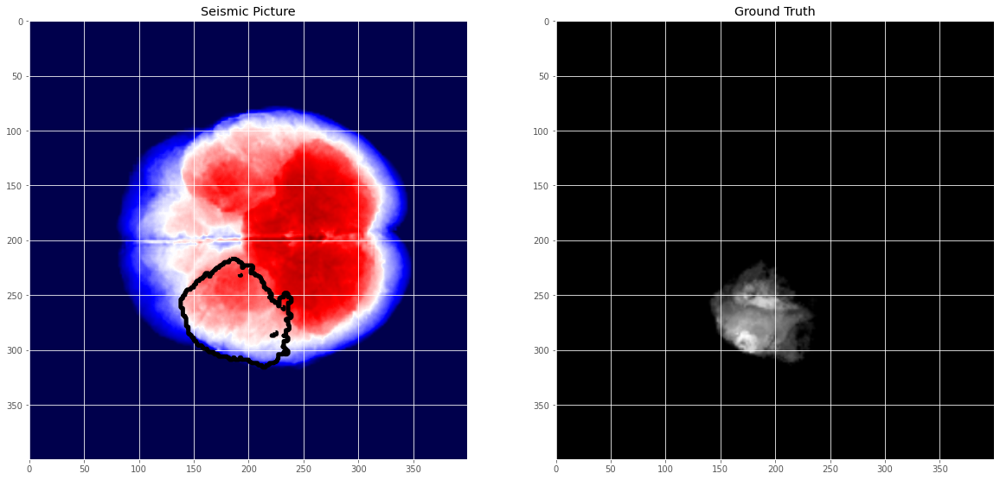

In [ ]:
# Check if training data looks all right
ix = random.randint(0, len(X_train))
has_mask = y_train[ix].max() > 0 # salt indicator

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20, 15))

ax1.imshow(X_train[ix, ..., 0], cmap = 'seismic', interpolation = 'bilinear')
if has_mask: # if Ground Truth
    # draw a boundary(contour) in the original image separating salt and non-salt areas
    ax1.contour(y_train[ix].squeeze(), colors = 'k', linewidths = 5, levels = [0.5])
ax1.set_title('Seismic Picture')

ax2.imshow(y_train[ix].squeeze(), cmap = 'gray', interpolation = 'bilinear')
ax2.set_title('Ground Truth')

In [ ]:
def conv2d_block(input_tensor, n_filters, kernel_size , batchnorm = True):
    """Function to add 2 convolutional layers with the parameters passed to it"""
    # first layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(input_tensor)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)

    # second layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(input_tensor)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)

    return x

In [ ]:
import keras.backend as K
def dice(y_true, y_pred, smooth=1):
    y_truef=K.flatten(y_true)
    y_predf=K.flatten(y_pred)
    And=K.sum(y_truef* y_predf)
    return((2* And + smooth) / (K.sum(y_truef) + K.sum(y_predf) + smooth))

In [ ]:
from keras import backend as K
def jaccard(y_true, y_pred, smooth=100):

    intersection = K.sum(K.abs(y_true * y_pred), axis=-1)
    sum_ = K.sum(K.abs(y_true) + K.abs(y_pred), axis=-1)
    jac = (intersection + smooth) / (sum_ - intersection + smooth)
    return (1 - jac) * smooth

In [ ]:
def get_unet(input_img, n_filters = 16, dropout = 0.1, batchnorm = True):
    """Function to define the UNET Model"""
    # Contracting Path
    c1 = conv2d_block(input_img, n_filters * 1, kernel_size = 5, batchnorm = batchnorm)
    p1 = MaxPooling2D((2, 2))(c1)
    p1 = Dropout(dropout)(p1)

    c2 = conv2d_block(p1, n_filters * 2, kernel_size = 5, batchnorm = batchnorm)
    p2 = MaxPooling2D((2, 2))(c2)
    p2 = Dropout(dropout)(p2)

    c3 = conv2d_block(p2, n_filters * 4, kernel_size = 5, batchnorm = batchnorm)
    p3 = MaxPooling2D((2, 2))(c3)
    p3 = Dropout(dropout)(p3)

    c4 = conv2d_block(p3, n_filters * 8, kernel_size = 3, batchnorm = batchnorm)
    p4 = MaxPooling2D((2, 2))(c4)
    p4 = Dropout(dropout)(p4)

    c5 = conv2d_block(p4, n_filters = n_filters * 16, kernel_size = 5, batchnorm = batchnorm)

    # Expansive Path
    u6 = Conv2DTranspose(n_filters * 8, (5, 5), strides = (2, 2), padding = 'same')(c5)
    u6 = concatenate([u6, c4])
    u6 = Dropout(dropout)(u6)
    c6 = conv2d_block(u6, n_filters * 8, kernel_size = 5, batchnorm = batchnorm)

    u7 = Conv2DTranspose(n_filters * 4, (5, 5), strides = (2, 2), padding = 'same')(c6)
    u7 = concatenate([u7, c3])
    u7 = Dropout(dropout)(u7)
    c7 = conv2d_block(u7, n_filters * 4, kernel_size = 5, batchnorm = batchnorm)

    u8 = Conv2DTranspose(n_filters * 2, (5, 5), strides = (2, 2), padding = 'same')(c7)
    u8 = concatenate([u8, c2])
    u8 = Dropout(dropout)(u8)
    c8 = conv2d_block(u8, n_filters * 2, kernel_size = 5, batchnorm = batchnorm)

    u9 = Conv2DTranspose(n_filters * 1, (5, 5), strides = (2, 2), padding = 'same')(c8)
    u9 = concatenate([u9, c1])
    u9 = Dropout(dropout)(u9)
    c9 = conv2d_block(u9, n_filters * 1, kernel_size = 5, batchnorm = batchnorm)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)
    model = Model(inputs=[input_img], outputs=[outputs])
    return model

In [ ]:
input_img = Input((im_height, im_width, 1), name='img')
model = get_unet(input_img, n_filters=16, dropout=0.05, batchnorm=True)
model.compile(optimizer=Adam(), loss="binary_crossentropy", metrics=["accuracy",dice,jaccard])

In [ ]:
model.summary()

Model: "functional_1"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
img (InputLayer)                [(None, 400, 400, 1) 0                                            
__________________________________________________________________________________________________
conv2d_1 (Conv2D)               (None, 400, 400, 16) 416         img[0][0]                        
__________________________________________________________________________________________________
batch_normalization_1 (BatchNor (None, 400, 400, 16) 64          conv2d_1[0][0]                   
__________________________________________________________________________________________________
activation_1 (Activation)       (None, 400, 400, 16) 0           batch_normalization_1[0][0]      
_______________________________________________________________________________________

In [ ]:
callbacks = [
    EarlyStopping(patience=10, verbose=1),
    ReduceLROnPlateau(factor=0.1, patience=5, min_lr=0.00001, verbose=1),
    ModelCheckpoint('model-tgs-salt.h5', verbose=1, save_best_only=True, save_weights_only=True)
]

In [ ]:
results = model.fit(X_train, y_train, batch_size=32, epochs=2, callbacks=callbacks,\
                    validation_data=(X_valid, y_valid))


Epoch 1/2
6/6 [==============================] - ETA: 0s - loss: 0.4028 - accuracy: 0.9334 - dice: 1.4911e-04 - jaccard: 0.3276  
Epoch 00001: val_loss improved from 1.64808 to 0.45202, saving model to model-tgs-salt.h5
6/6 [==============================] - 389s 65s/step - loss: 0.4028 - accuracy: 0.9334 - dice: 1.4911e-04 - jaccard: 0.3276 - val_loss: 0.4520 - val_accuracy: 0.9026 - val_dice: 1.1368e-04 - val_jaccard: 0.3435
Epoch 2/2
6/6 [==============================] - ETA: 0s - loss: 0.3818 - accuracy: 0.9369 - dice: 1.4860e-04 - jaccard: 0.3144  
Epoch 00002: val_loss did not improve from 0.45202
6/6 [==============================] - 389s 65s/step - loss: 0.3818 - accuracy: 0.9369 - dice: 1.4860e-04 - jaccard: 0.3144 - val_loss: 0.5937 - val_accuracy: 0.8233 - val_dice: 1.8351e-04 - val_jaccard: 0.4247


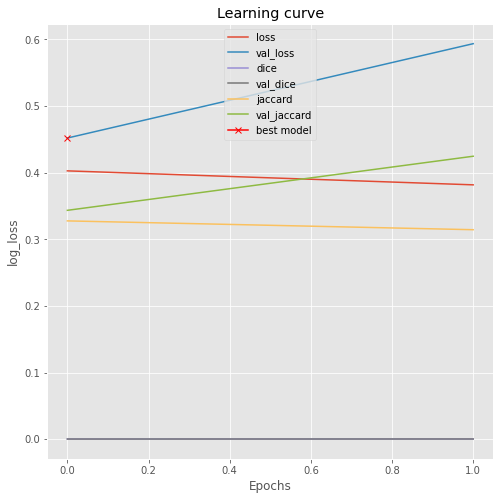

In [ ]:
plt.figure(figsize=(8, 8))
plt.title("Learning curve")
plt.plot(results.history["loss"], label="loss")
plt.plot(results.history["val_loss"], label="val_loss")
plt.plot(results.history["dice"], label="dice")
plt.plot(results.history["val_dice"], label="val_dice")
plt.plot(results.history["jaccard"], label="jaccard")
plt.plot(results.history["val_jaccard"], label="val_jaccard")
plt.plot( np.argmin(results.history["val_loss"]), np.min(results.history["val_loss"]), marker="x", color="r", label="best model")
plt.xlabel("Epochs")
plt.ylabel("log_loss")
plt.legend();

In [ ]:
# Load best model
model.load_weights('model-tgs-salt.h5')

In [ ]:
# Evaluate on validation set (this must be equals to the best log_loss)
model.evaluate(X_valid, y_valid, verbose=1)

1/1 [==============================] - 0s 2ms/step - loss: 0.4520 - accuracy: 0.9026 - dice: 1.1368e-04 - jaccard: 0.3435


[0.45201849937438965,
 0.9025916457176208,
 0.00011367977276677266,
 0.3434980511665344]

In [ ]:
model.metrics_names

['loss', 'accuracy', 'dice', 'jaccard']

In [ ]:
# Predict on train, val and test
preds_train = model.predict(X_train, verbose=1)
preds_val = model.predict(X_valid, verbose=1)

1/1 [==============================] - 0s 6ms/step


In [ ]:
# Threshold predictions
preds_train_t = (preds_train > 0.5).astype(np.uint8)
preds_val_t = (preds_val > 0.5).astype(np.uint8)

In [ ]:
def plot_sample(X, y, preds, binary_preds, ix=None):
    """Function to plot the results"""
    for ix in range(0,20):
        fig, ax = plt.subplots(1, 4, figsize=(20, 10))
        ax[0].imshow(X[ix, ..., 0], cmap='seismic')
        ax[0].set_title('MRI')

        ax[1].imshow(y[ix].squeeze())
        ax[1].set_title('Mask/OT')

        ax[2].imshow(preds[ix].squeeze(), vmin=0, vmax=1)
        ax[2].set_title('OT Predicted')

        ax[3].imshow(binary_preds[ix].squeeze(), vmin=0, vmax=1)
        ax[3].set_title('OT Predicted binary');

/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  after removing the cwd from sys.path.


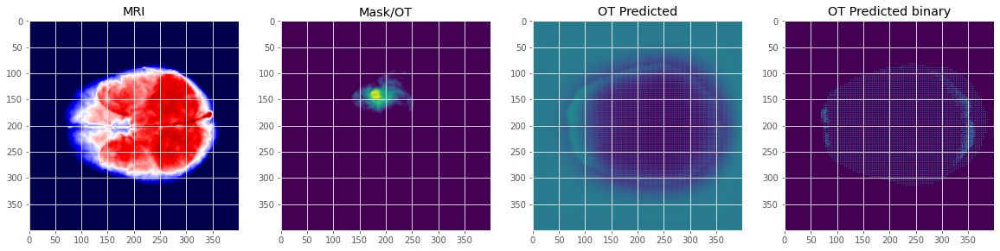

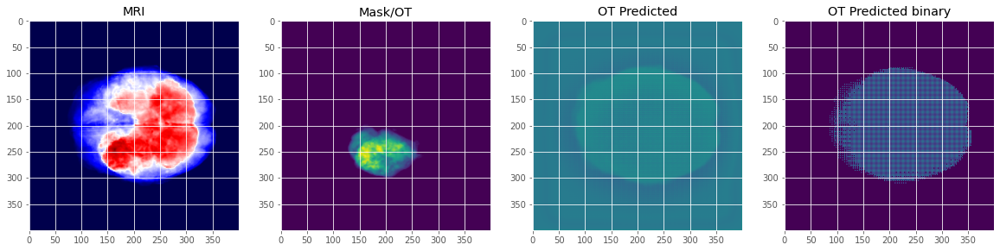

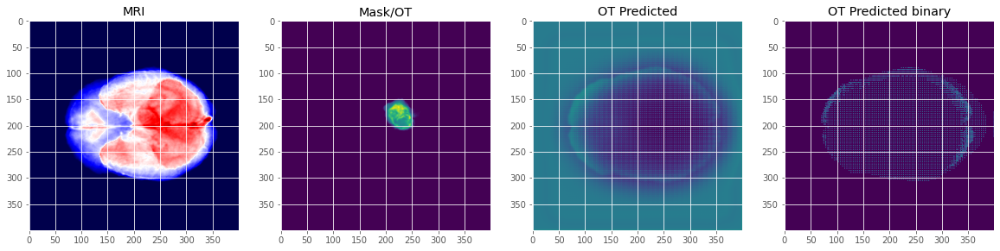

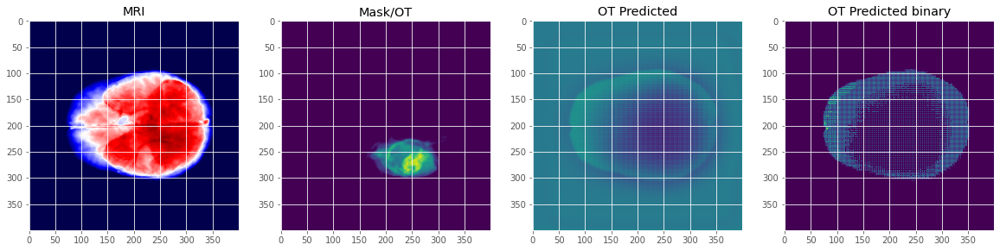

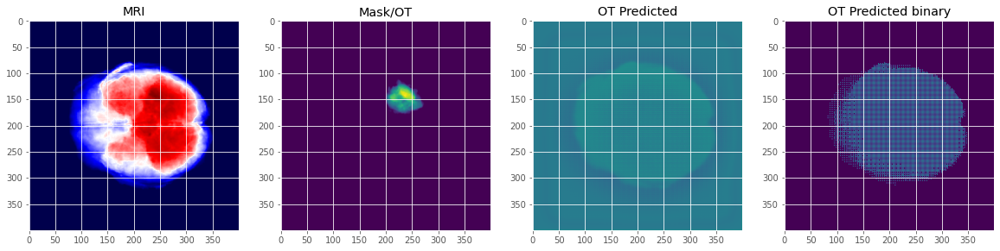

...

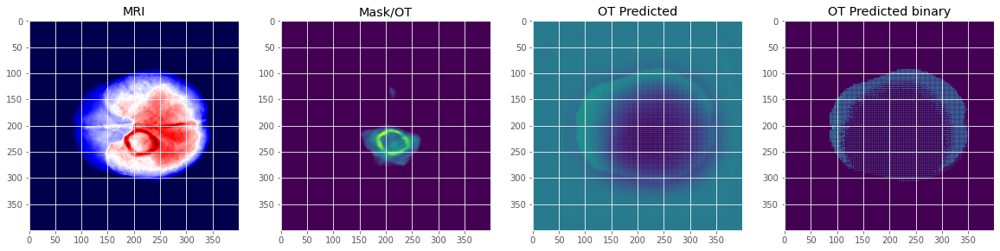

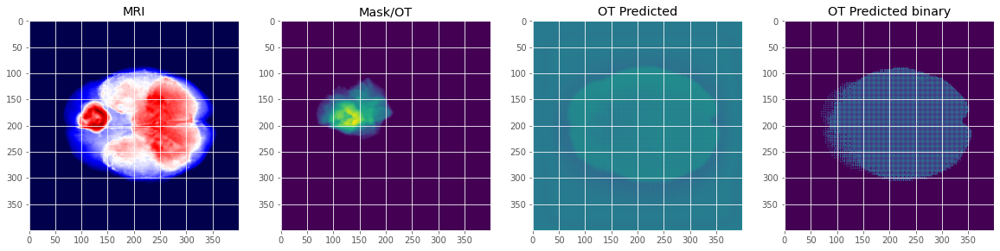

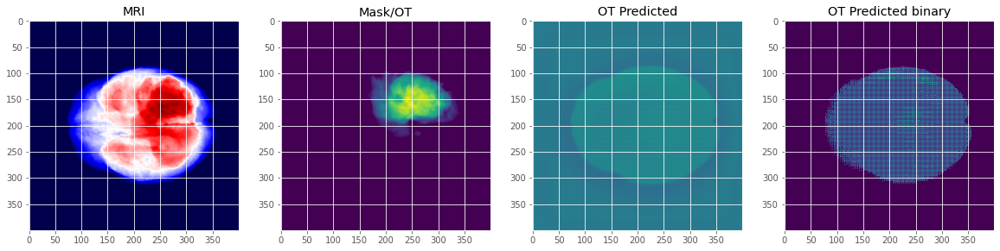

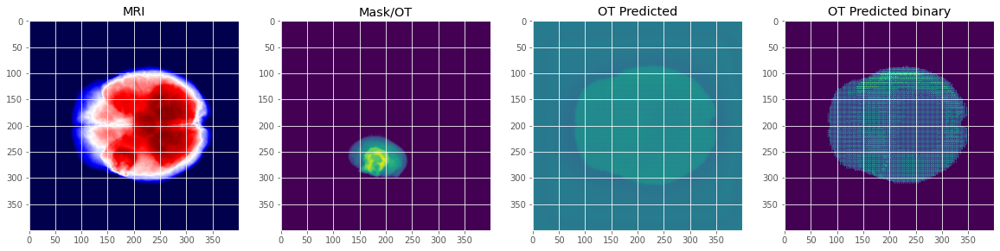

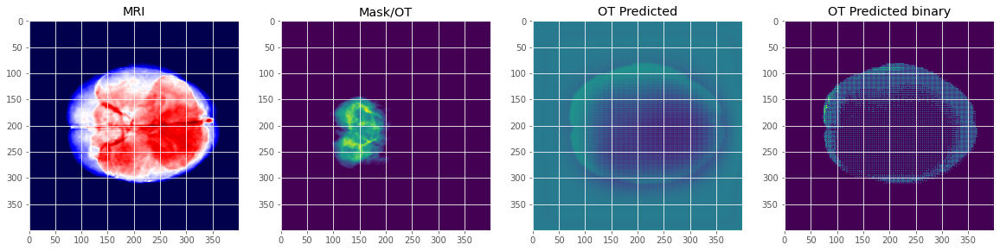

In [ ]:
# Check if training data looks all right
plot_sample(X_train, y_train, preds_train, preds_train_t, ix=14)

# Check if valid data looks all right
plot_sample(X_valid, y_valid, preds_val, preds_val_t, ix=19)

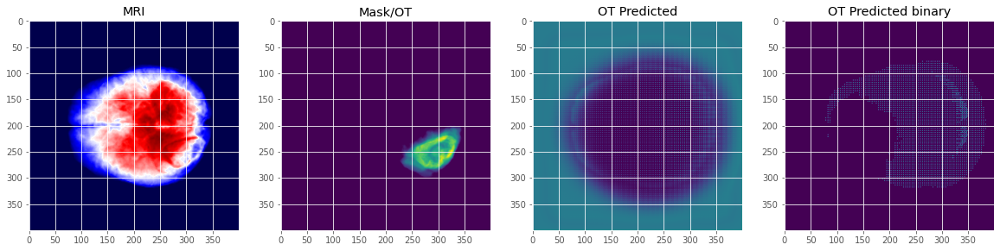

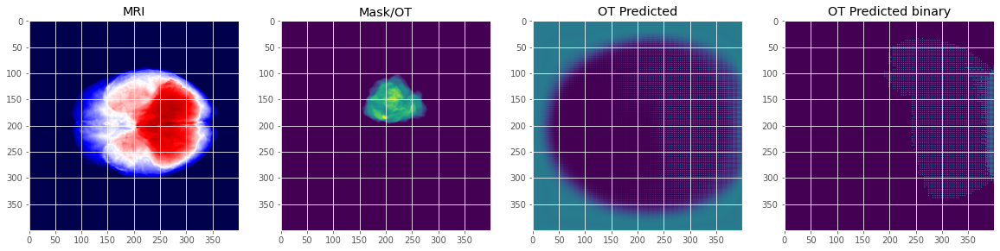

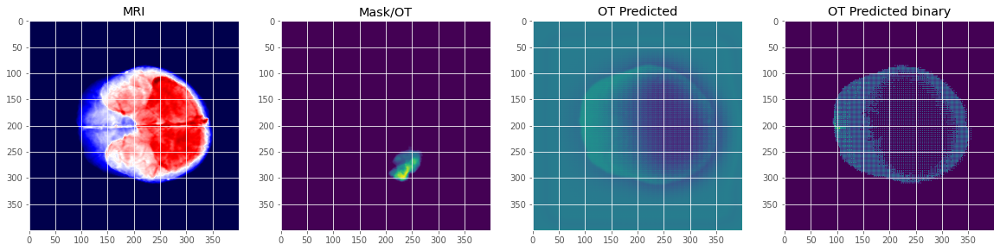

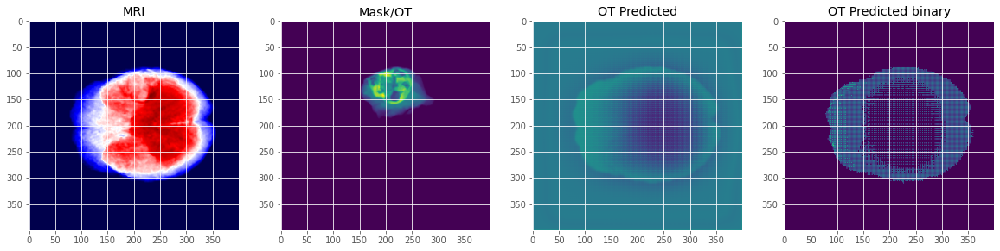

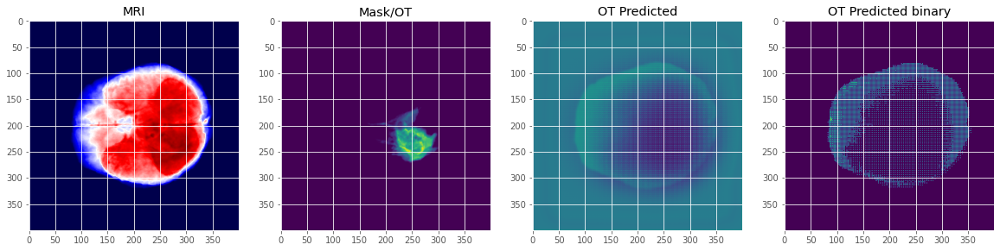

...

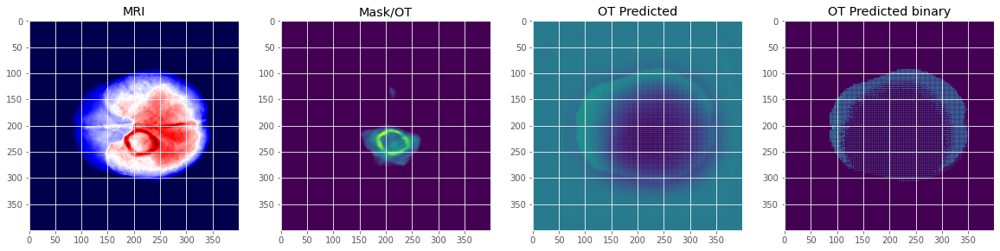

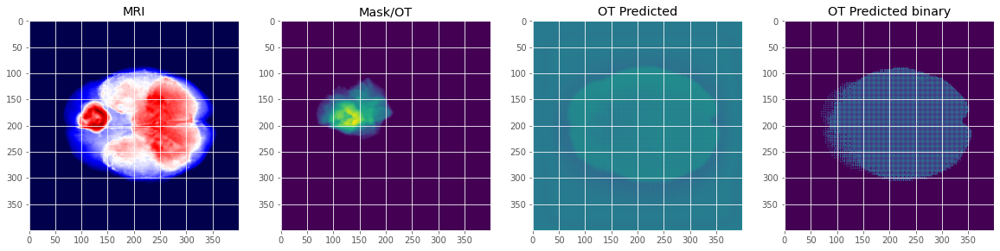

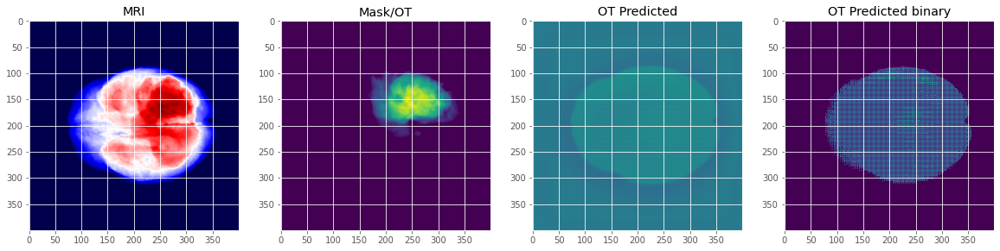

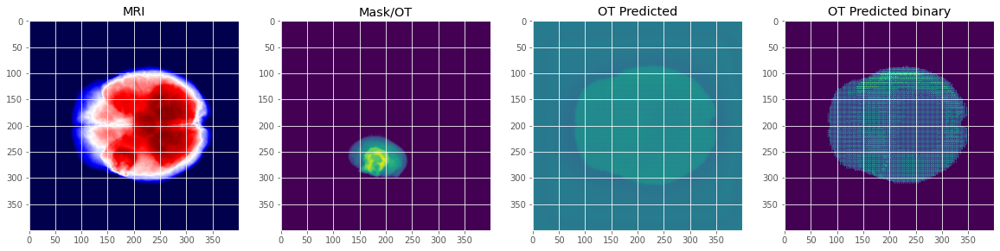

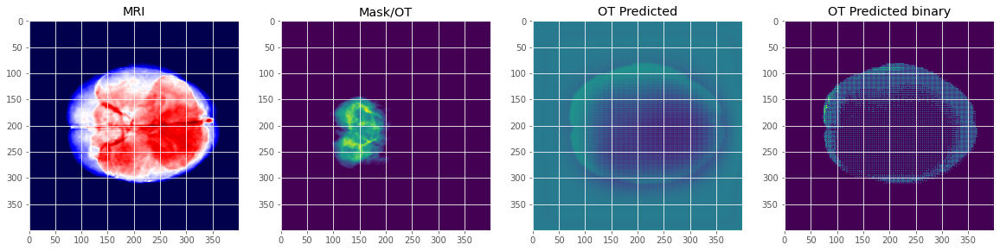

In [ ]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)